# 5. Transient conduction

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 1 and 4

Chapter 1 cooled the water in a pipe with a single temperature for the whole pipe: the
*lumped* model. That works when conduction inside the body is fast compared with the heat
transfer at its surface. Steel parts quenched in a heat-treatment shop are the opposite
case. A bar of steel at 850 °C plunged into oil or water cools at its surface long before
its centre, and the properties it ends up with depend on how fast each part of it cooled.
This chapter asks how fast the centre of a steel bar cools in oil and in water, how this
changes with the size of the bar, and when the lumped model can be trusted.

The tools are the exact series solutions for the slab, the cylinder and the sphere,
obtained by separation of variables as in Chapter 4, and a Crank–Nicolson finite-volume
solver that checks them.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np

try:
    from engtransport import reference, transient
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    from engtransport import reference, transient
from engtransport.plotting import panel_label, use_style

use_style()

## 5.1 The lumped model and the Biot number

If the temperature inside a body of volume $V$, surface $A$, density $\rho$ and specific
heat $c$ is uniform, its energy balance is

$$
\rho c V \frac{dT}{dt} = -hA\,(T - T_\infty) ,
\tag{5.1}
$$

and the excess temperature decays exponentially with a time constant $\tau$:

$$
\frac{T - T_\infty}{T_i - T_\infty} = e^{-t/\tau}, \qquad \tau = \frac{\rho c V}{hA} .
\tag{5.2}
$$

The temperature inside is nearly uniform when the resistance to conduction across the
body, about $L_c/kA$, is small compared with the resistance of the surface film, $1/hA$.
Their ratio is the Biot number

$$
\mathrm{Bi}_c = \frac{hL_c}{k}, \qquad L_c = \frac{V}{A} ,
\tag{5.3}
$$

with $L_c$ equal to the half-thickness $L$ of a slab, $R/2$ for a long cylinder and $R/3$ for a
sphere. The usual rule is that the lumped model is good when $\mathrm{Bi}_c < 0.1$;
Section 5.5 tests it.

## 5.2 Inside the body: series solutions

When the temperature inside is not uniform, it obeys the heat equation. For a slab
($m = 0$), a long cylinder ($m = 1$) or a sphere ($m = 2$), with $r$ the distance from the
mid-plane or the centre,

$$
\frac{\partial T}{\partial t} = \frac{\alpha}{r^m}\,\frac{\partial}{\partial r}
\left(r^m\,\frac{\partial T}{\partial r}\right), \qquad \alpha = \frac{k}{\rho c} ,
\tag{5.4}
$$

with $-k\,\partial T/\partial r = h(T - T_\infty)$ at the surface $r = R$ and a uniform
initial temperature $T_i$. In terms of $\theta = (T - T_\infty)/(T_i - T_\infty)$, the
Fourier number $\mathrm{Fo} = \alpha t/R^2$ and the Biot number $\mathrm{Bi} = hR/k$, a
product of a function of time and a function of position separates Eq. (5.4), as in
Chapter 4. The time part is $e^{-\lambda^2 \mathrm{Fo}}$. For the slab the position part is
$\cos(\lambda r/R)$, and the surface condition fixes the allowed values of $\lambda$:

$$
\theta = \sum_{n=1}^{\infty} C_n\, e^{-\lambda_n^2 \mathrm{Fo}} \cos\frac{\lambda_n r}{R},
\qquad \lambda_n \tan\lambda_n = \mathrm{Bi}, \qquad
C_n = \frac{4\sin\lambda_n}{2\lambda_n + \sin 2\lambda_n} .
\tag{5.5}
$$

For the cylinder the position part is the Bessel function $J_0(\lambda r/R)$, and for the
sphere it is $\sin(\lambda r/R)/(\lambda r/R)$:

$$
\lambda_n \frac{J_1(\lambda_n)}{J_0(\lambda_n)} = \mathrm{Bi}, \quad
C_n = \frac{2}{\lambda_n}\frac{J_1(\lambda_n)}{J_0^2(\lambda_n) + J_1^2(\lambda_n)}
\quad\text{(cylinder)} ,
\tag{5.6}
$$

$$
1 - \lambda_n\cot\lambda_n = \mathrm{Bi}, \quad
C_n = \frac{4(\sin\lambda_n - \lambda_n\cos\lambda_n)}{2\lambda_n - \sin 2\lambda_n}
\quad\text{(sphere)} .
\tag{5.7}
$$

Each term decays as $e^{-\lambda_n^2 \mathrm{Fo}}$, and the $\lambda_n$ grow roughly as $n\pi$,
so after a short time only the first term is left. For $\mathrm{Fo} > 0.2$ the centre
temperature is close to

$$
\theta_0 \approx C_1\, e^{-\lambda_1^2 \mathrm{Fo}} .
\tag{5.8}
$$

These are the solutions behind the *Heisler charts* of the older textbooks.
`transient.transient_1d_series` sums them.

In [2]:
Bi_demo = 1.0
for geom in ("slab", "cylinder", "sphere"):
    res = transient.transient_1d_series(np.array([0.0]), 0.2, Bi_demo, geom, n_modes=15)
    lam = res["eigenvalues"]
    print(f"{geom:8s} Bi = 1: lambda_1..3 = {lam[0]:.4f}, {lam[1]:.4f}, {lam[2]:.4f};"
          f" centre at Fo = 0.2: {res['theta_star'][0]:.4f}")

slab     Bi = 1: lambda_1..3 = 0.8603, 3.4256, 6.4373; centre at Fo = 0.2: 0.9506
cylinder Bi = 1: lambda_1..3 = 1.2558, 4.0795, 7.1558; centre at Fo = 0.2: 0.8702
sphere   Bi = 1: lambda_1..3 = 1.5708, 4.7124, 7.8540; centre at Fo = 0.2: 0.7723


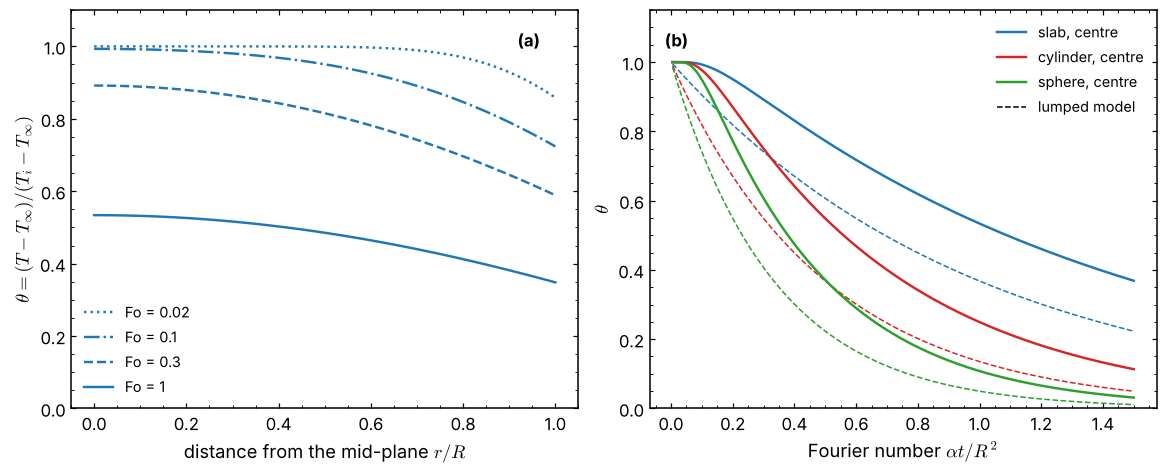

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.2))
xs = np.linspace(0, 1, 101)
for Fo_val, style in ((0.02, ":"), (0.1, "-."), (0.3, "--"), (1.0, "-")):
    ax1.plot(xs, transient.transient_1d_series(xs, Fo_val, Bi_demo, "slab")["theta_star"], "C0" + style,
             label=f"Fo = {Fo_val:g}")
ax1.set_xlabel(r"distance from the mid-plane $r/R$")
ax1.set_ylabel(r"$\theta = (T - T_\infty)/(T_i - T_\infty)$")
ax1.set_ylim(0, 1.1)
ax1.legend(loc="lower left")
panel_label(ax1, "(a)", x=0.88)

Fos = np.linspace(0.005, 1.5, 200)
for geom, color in (("slab", "C0"), ("cylinder", "C3"), ("sphere", "C2")):
    m = {"slab": 0, "cylinder": 1, "sphere": 2}[geom]
    centre = [transient.transient_1d_series(np.array([0.0]), F, Bi_demo, geom)["theta_star"][0] for F in Fos]
    ax2.plot(Fos, centre, color, label=f"{geom}, centre")
    ax2.plot(Fos, np.exp(-(m + 1) * Bi_demo * Fos), color + "--", lw=1)   # lumped: t/tau = (m+1) Bi Fo
ax2.plot([], [], "k--", lw=1, label="lumped model")
ax2.set_xlabel(r"Fourier number $\alpha t/R^2$")
ax2.set_ylabel(r"$\theta$")
ax2.set_ylim(0, 1.15)
ax2.legend(loc="upper right")
panel_label(ax2, "(b)")
plt.show()

**Figure 5.1.** (a) Temperature in a slab with $\mathrm{Bi} = 1$ at four Fourier numbers,
Eq. (5.5). (b) Centre temperatures of a slab, a long cylinder and a sphere with
$\mathrm{Bi} = hR/k = 1$, from the series (5.5)–(5.7), and the lumped model (5.2) for each
(dashed), with $t/\tau = (m + 1)\,\mathrm{Bi}\,\mathrm{Fo}$.

At $\mathrm{Bi} = 1$ the lumped model is badly wrong for the centre, and always on the same
side: it starts cooling the centre at once, while the real centre stays at its initial
temperature until the cooling at the surface reaches it, and it stays ahead afterwards.
The sphere, which has the most surface for its volume, cools fastest.

## 5.3 Quenching a steel bar

A steel bar at 850 °C is quenched in oil at 60 °C or in water at 30 °C. The rate at which
each part of it cools through the range 800–500 °C decides what structure the steel takes
and so how hard it becomes; the time to cool through that range, $t_{8/5}$, is a convenient
measure. Take $k = 30$ W/(m K), $\rho = 7800$ kg/m³ and $c = 600$ J/(kg K), values typical of
carbon steel in this range, so $\alpha = 6.4 \times 10^{-6}$ m²/s. The heat transfer
coefficient of a quench is far from constant, because the liquid boils on the hot steel;
we take an average of $h = 1000$ W/(m² K) for oil and $5000$ W/(m² K) for water (Exercise 4
lets $h$ vary).

The bar is long, so it is a cylinder. For a 50 mm bar, $\mathrm{Bi} = hR/k$ is 0.83 in oil
and 4.2 in water: neither quench is lumped.

In [4]:
k_st, rho_st, c_st = 30.0, 7800.0, 600.0
rho_c = rho_st * c_st
alpha = k_st / rho_c
T_init = 850.0
quenchants = {"oil": (1000.0, 60.0), "water": (5000.0, 30.0)}


def crossing(t, T, value):
    """Time at which a falling temperature history passes a value."""
    i = int(np.argmax(T < value))
    if i == 0:
        return 0.0
    return float(np.interp(value, [T[i], T[i - 1]], [t[i], t[i - 1]]))


def series_history(D, h, T_f, t_end, n_t=1500, r_star=0.0):
    """Temperature history at r/R = r_star of a long cylinder, from Eq. (5.6)."""
    R = D / 2
    t = np.linspace(0, t_end, n_t)
    Bi = h * R / k_st
    theta = [transient.transient_1d_series(np.array([r_star]), alpha * tt / R**2, Bi, "cylinder")["theta_star"][0]
             if tt > 0 else 1.0 for tt in t]
    return t, T_f + (T_init - T_f) * np.array(theta)


def t85(D, h, T_f, r_star=0.0):
    t_end = 4 * (D / 2) ** 2 / alpha + 4 * rho_c * D / (4 * h)
    t, T = series_history(D, h, T_f, t_end, r_star=r_star)
    return crossing(t, T, 500.0) - crossing(t, T, 800.0), crossing(t, T, 500.0)


def t85_lumped(D, h, T_f):
    tau = rho_c * (D / 2) / (2 * h)                  # V/A = R/2
    return tau * math.log((T_init - T_f) / (500 - T_f)) - tau * math.log((T_init - T_f) / (800 - T_f))


print("bar      quench   Bi = hR/k   t8/5 centre   t8/5 at r = 0.9R   lumped   centre at 500 C after")
for D in (0.025, 0.05, 0.10):
    for name, (h, T_f) in quenchants.items():
        tc, t500 = t85(D, h, T_f)
        tsurf, _ = t85(D, h, T_f, r_star=0.9)
        print(f"{1e3 * D:4.0f} mm  {name:6s}  {h * D / 2 / k_st:8.2f}   {tc:9.1f} s   {tsurf:12.1f} s   "
              f"{t85_lumped(D, h, T_f):6.1f} s   {t500:6.1f} s")

bar      quench   Bi = hR/k   t8/5 centre   t8/5 at r = 0.9R   lumped   centre at 500 C after


  25 mm  oil         0.42        17.0 s           15.8 s     15.2 s     22.0 s


  25 mm  water       2.08         5.2 s            2.4 s      2.9 s      7.9 s


  50 mm  oil         0.83        38.7 s           30.5 s     30.4 s     53.5 s


  50 mm  water       4.17        15.3 s            4.3 s      5.8 s     24.8 s


 100 mm  oil         1.67        97.5 s           54.6 s     60.8 s    145.1 s


 100 mm  water       8.33        50.6 s            8.8 s     11.6 s     84.5 s


For a 50 mm bar the centre takes 39 s to cool from 800 to 500 °C in oil and 15 s in water.
Near the surface, at $0.9R$, these become 31 s and 4.3 s: in water the outside of the bar
cools three and a half times as fast as its centre, which is why a water-quenched bar can have a hard
case and a softer core, and why water quenching cracks some steels. The size of the bar
matters more than the quenchant. Doubling the diameter more than doubles $t_{8/5}$ at the
centre, and the centre of a 100 mm bar quenched in water (51 s) cools more slowly than that
of a 50 mm bar quenched in oil.

The lumped model, with $\mathrm{Bi}_c = h(R/2)/k = 0.42$ for the 50 mm bar in oil, gives
30 s instead of 39 s. It assumes that the centre cools with the surface, so it is always
optimistic about the centre.

50 mm bar, bath at 45 C: t8/5 at the centre 15.6 s with h = 5000, 10.3 s in the limit of an infinite h


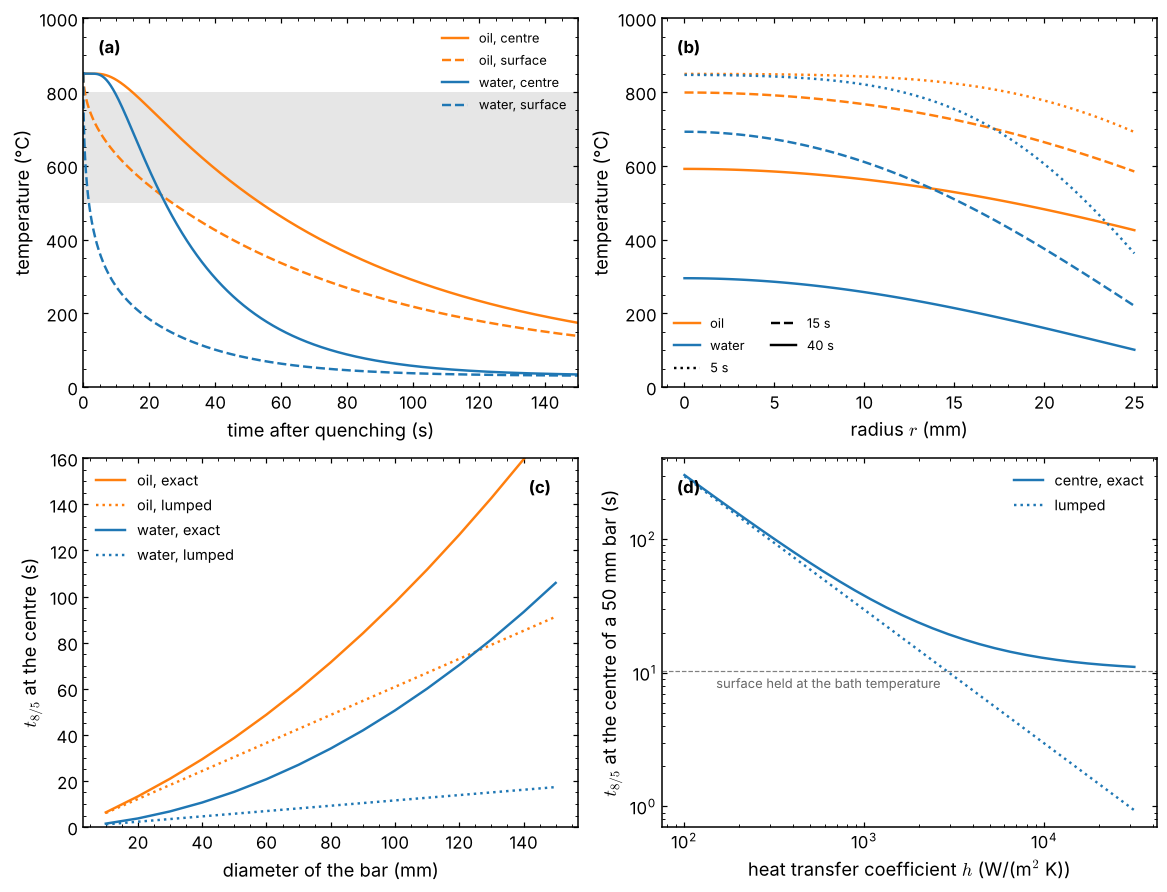

In [5]:
h_range = np.logspace(2, 4.5, 30)
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.0))
D0 = 0.05
ax = axes[0, 0]
for (name, (h, T_f)), color in zip(quenchants.items(), ("C1", "C0")):
    t, Tc = series_history(D0, h, T_f, 150.0)
    _, Ts = series_history(D0, h, T_f, 150.0, r_star=1.0)
    ax.plot(t, Tc, color, label=f"{name}, centre")
    ax.plot(t, Ts, color + "--", label=f"{name}, surface")
ax.axhspan(500, 800, color="0.9", lw=0)
ax.set_xlabel("time after quenching (s)")
ax.set_ylabel("temperature (°C)")
ax.set_xlim(0, 150)
ax.set_ylim(0, 1000)
ax.legend(loc="upper right", fontsize=8.5)
panel_label(ax, "(a)")

ax = axes[0, 1]
rr = np.linspace(0, 1, 101)
for (name, (h, T_f)), color in zip(quenchants.items(), ("C1", "C0")):
    Bi = h * D0 / 2 / k_st
    for t_snap, style in ((5.0, ":"), (15.0, "--"), (40.0, "-")):
        th = transient.transient_1d_series(rr, alpha * t_snap / (D0 / 2) ** 2, Bi, "cylinder")["theta_star"]
        ax.plot(rr * D0 / 2 * 1e3, T_f + (T_init - T_f) * th, color + style)
for label, handle in (("oil", "C1-"), ("water", "C0-"), ("5 s", "k:"), ("15 s", "k--"), ("40 s", "k-")):
    ax.plot([], [], handle, label=label)
ax.set_xlabel("radius $r$ (mm)")
ax.set_ylabel("temperature (°C)")
ax.set_ylim(0, 1000)
ax.legend(loc="lower left", fontsize=8.5, ncol=2)
panel_label(ax, "(b)")

ax = axes[1, 0]
Ds = np.linspace(0.01, 0.15, 15)
for (name, (h, T_f)), color in zip(quenchants.items(), ("C1", "C0")):
    ax.plot(Ds * 1e3, [t85(D, h, T_f)[0] for D in Ds], color, label=f"{name}, exact")
    ax.plot(Ds * 1e3, [t85_lumped(D, h, T_f) for D in Ds], color + ":", label=f"{name}, lumped")
ax.set_xlabel("diameter of the bar (mm)")
ax.set_ylabel(r"$t_{8/5}$ at the centre (s)")
ax.set_ylim(0, 160)
ax.legend(loc="upper left")
panel_label(ax, "(c)", x=0.9)

ax = axes[1, 1]
ax.loglog(h_range, [t85(D0, h, 45.0)[0] for h in h_range], "C0", label="centre, exact")
ax.loglog(h_range, [t85_lumped(D0, h, 45.0) for h in h_range], "C0:", label="lumped")
t_cond = t85(D0, 1e7, 45.0)[0]                       # surface held at the bath temperature
print(f"50 mm bar, bath at 45 C: t8/5 at the centre {t85(D0, 5000.0, 45.0)[0]:.1f} s with h = 5000,"
      f" {t_cond:.1f} s in the limit of an infinite h")
ax.axhline(t_cond, color="0.5", lw=0.8, ls="--")
ax.text(150, t_cond * 0.75, "surface held at the bath temperature", fontsize=8.5, color="0.4")
ax.set_xlabel(r"heat transfer coefficient $h$ (W/(m$^2$ K))")
ax.set_ylabel(r"$t_{8/5}$ at the centre of a 50 mm bar (s)")
ax.legend(loc="upper right")
panel_label(ax, "(d)")
plt.show()

**Figure 5.2.** Quenching a long steel bar from 850 °C. (a) Temperatures at the centre and
the surface of a 50 mm bar in oil and in water; the shaded band is 800–500 °C. (b)
Temperature across the bar at three times. (c) Time for the centre to cool from 800 to
500 °C against the diameter, exact (5.6) and lumped (5.2). (d) The same time for a 50 mm
bar against the heat transfer coefficient (bath at 45 °C); the dashed line is the limit of
an infinitely severe quench.

Figure 5.2d shows why a more severe quench stops helping. As $h$ grows, the surface
approaches the bath temperature and the cooling of the centre is limited by conduction
inside the bar, which depends on $R^2/\alpha$ alone. For a 50 mm bar this limit is a
$t_{8/5}$ of 10.3 s, and water at $h = 5000$ W/(m² K), with 15.6 s, is already close to it.

## 5.4 Checks

`reference.transient_conduction_fv` solves Eq. (5.4) by finite volumes in space and the
Crank–Nicolson scheme in time: the time derivative is balanced against the average of the
fluxes at the old and the new time, which makes the scheme second order in time as well
as in space. It also keeps an account of the heat stored and the heat lost through the
surface, which must agree.

*The series against finite volumes.* For each shape at $\mathrm{Bi} = 1$ and
$\mathrm{Fo} = 0.3$, with the time step halved whenever the cells are halved.

*Crank–Nicolson against backward Euler.* With a fine grid, the error in time alone.

*The lumped model.* Its error in the time to remove 90 % of the stored heat, against
$\mathrm{Bi}_c$, for all three shapes.

*The one-term approximation (5.8).* Its error at the centre against Fo.

In [6]:
Bi_chk, Fo_chk, R_chk = 1.0, 0.3, 1.0
cells = np.array([10, 20, 40, 80, 160])
errs = {}
for geom in ("slab", "cylinder", "sphere"):
    e = []
    for n in cells:
        out = reference.transient_conduction_fv(R_chk, 1.0, 1.0, Bi_chk, 0.0, 1.0, geom, n_cells=n, t_end=Fo_chk,
                                                n_steps=2 * n)
        exact = transient.transient_1d_series(out["r"], Fo_chk, Bi_chk, geom)["theta_star"]
        e.append(np.max(np.abs(out["T"][-1] - exact)))
        balance = abs(out["Q_lost"][-1] - out["Q_stored"][-1]) / out["Q_stored"][-1]
    errs[geom] = np.array(e)
    order = -np.polyfit(np.log(cells), np.log(errs[geom]), 1)[0]
    print(f"{geom:8s}: largest error {errs[geom][-1]:.1e} with 160 cells, order {order:.2f}, energy balance {balance:.0e}")

steps = np.array([5, 10, 20, 40, 80])
ref_fine = transient.transient_1d_series(np.array([0.0]), Fo_chk, Bi_chk, "cylinder")["theta_star"][0]
err_cn, err_be = [], []
for ns in steps:
    for th, store in ((0.5, err_cn), (1.0, err_be)):
        out = reference.transient_conduction_fv(R_chk, 1.0, 1.0, Bi_chk, 0.0, 1.0, "cylinder", n_cells=400,
                                                t_end=Fo_chk, n_steps=ns, theta=th)
        exact = transient.transient_1d_series(out["r"][:1], Fo_chk, Bi_chk, "cylinder")["theta_star"][0]
        store.append(abs(out["T"][-1][0] - exact))
err_cn, err_be = np.array(err_cn), np.array(err_be)
print(f"time step only (400 cells): Crank-Nicolson order {-np.polyfit(np.log(steps), np.log(err_cn), 1)[0]:.2f},"
      f" backward Euler order {-np.polyfit(np.log(steps), np.log(err_be), 1)[0]:.2f}")

slab    : largest error 1.1e-06 with 160 cells, order 1.99, energy balance 1e-12
cylinder: largest error 3.6e-07 with 160 cells, order 1.99, energy balance 2e-13
sphere  : largest error 5.6e-07 with 160 cells, order 2.00, energy balance 6e-14
time step only (400 cells): Crank-Nicolson order 1.98, backward Euler order 0.91


In [7]:
def time_to_fraction(geom, Bi, fraction=0.9):
    """Fo at which a fraction of the stored heat has been removed, from the series."""
    Fos = np.linspace(1e-4, 40 / max(Bi, 1e-3), 4000)
    removed = np.array([transient.transient_1d_series(np.array([0.0]), F, Bi, geom)["Q_over_Qmax"] for F in Fos])
    return float(np.interp(fraction, removed, Fos))


Bic_list = np.logspace(-2.5, 0.5, 13)
lumped_err = {}
for geom, m in (("slab", 0), ("cylinder", 1), ("sphere", 2)):
    e = []
    for Bic in Bic_list:
        Bi = (m + 1) * Bic                            # Bi = hR/k = (m + 1) Bi_c
        Fo_exact = time_to_fraction(geom, Bi)
        Fo_lumped = math.log(10) / ((m + 1) * Bi)     # exp(-t/tau) = 0.1
        e.append(Fo_lumped / Fo_exact - 1)
    lumped_err[geom] = np.array(e)
for geom in lumped_err:
    print(f"{geom:8s}: lumped time for 90 % of the heat off by {np.interp(math.log(0.1), np.log(Bic_list), lumped_err[geom]):+.1%}"
          f" at Bi_c = 0.1, {np.interp(math.log(1.0), np.log(Bic_list), lumped_err[geom]):+.0%} at Bi_c = 1")

Fo_list = np.logspace(-2, 0.3, 40)
one_term_err = {}
for Bi in (0.1, 1.0, 10.0):
    full = np.array([transient.transient_1d_series(np.array([0.0]), F, Bi, "cylinder")["theta_star"][0] for F in Fo_list])
    res = transient.transient_1d_series(np.array([0.0]), 1.0, Bi, "cylinder")
    lam1 = res["eigenvalues"][0]
    from scipy.special import j0, j1
    C1 = 2 / lam1 * j1(lam1) / (j0(lam1) ** 2 + j1(lam1) ** 2)
    one_term_err[Bi] = np.abs(C1 * np.exp(-lam1**2 * Fo_list) / full - 1)
    print(f"cylinder, Bi = {Bi:4g}: one-term error at the centre {np.interp(0.2, Fo_list, one_term_err[Bi]):.1%} at Fo = 0.2")

slab    : lumped time for 90 % of the heat off by -3.2% at Bi_c = 0.1, -26% at Bi_c = 1
cylinder: lumped time for 90 % of the heat off by -4.8% at Bi_c = 0.1, -35% at Bi_c = 1
sphere  : lumped time for 90 % of the heat off by -5.7% at Bi_c = 0.1, -40% at Bi_c = 1
cylinder, Bi =  0.1: one-term error at the centre 0.2% at Fo = 0.2
cylinder, Bi =    1: one-term error at the centre 1.2% at Fo = 0.2
cylinder, Bi =   10: one-term error at the centre 1.0% at Fo = 0.2


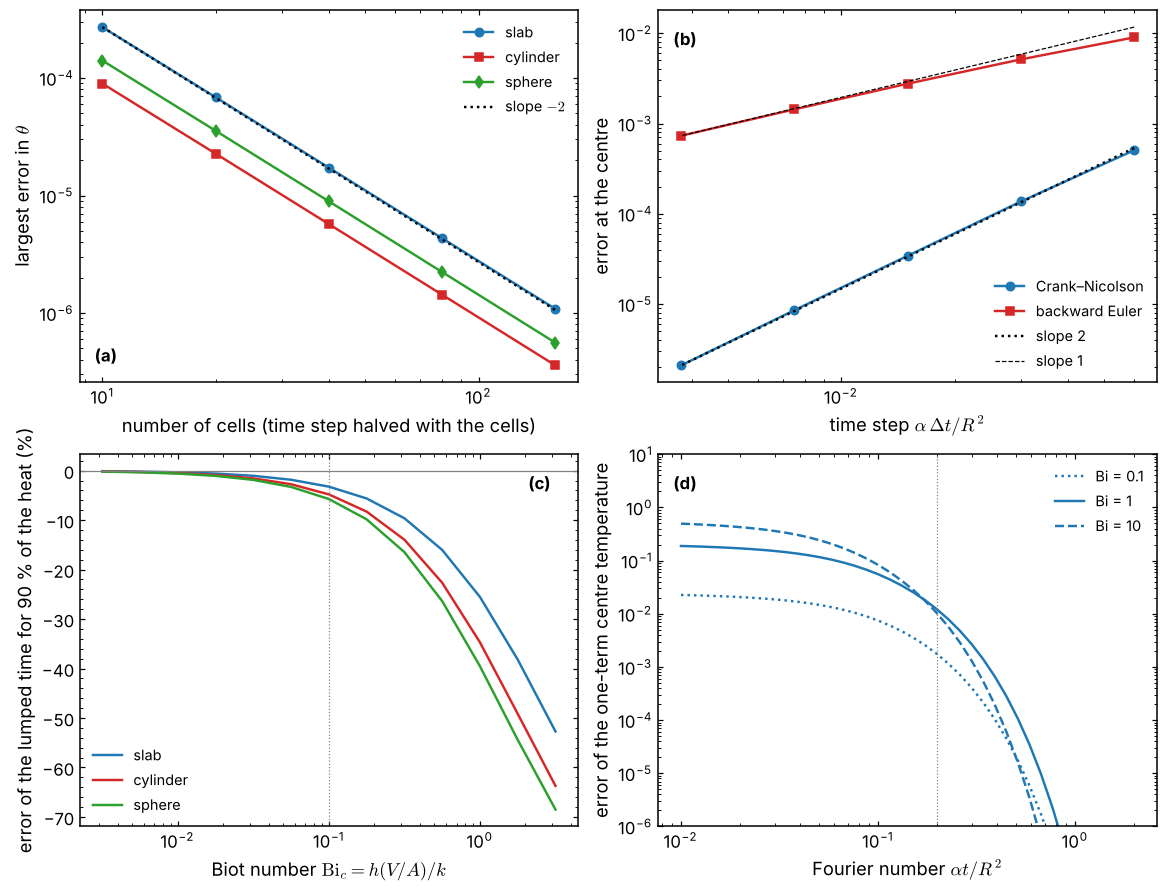

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.0))
ax = axes[0, 0]
for (geom, e), marker, color in zip(errs.items(), "osd", ("C0", "C3", "C2")):
    ax.loglog(cells, e, marker + "-", color=color, label=geom)
ax.loglog(cells, errs["slab"][0] * (cells[0] / cells) ** 2, "k:", label=r"slope $-2$")
ax.set_xlabel("number of cells (time step halved with the cells)")
ax.set_ylabel(r"largest error in $\theta$")
ax.legend(loc="upper right")
panel_label(ax, "(a)", y=0.1)

ax = axes[0, 1]
ax.loglog(Fo_chk / steps, err_cn, "o-", label="Crank–Nicolson")
ax.loglog(Fo_chk / steps, err_be, "s-", color="C3", label="backward Euler")
dts = Fo_chk / steps
ax.loglog(dts, err_cn[-1] * (dts / dts[-1]) ** 2, "k:", label="slope 2")
ax.loglog(dts, err_be[-1] * (dts / dts[-1]), "k--", lw=0.8, label="slope 1")
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel(r"time step $\alpha\,\Delta t/R^2$")
ax.set_ylabel("error at the centre")
ax.legend(loc="lower right")
panel_label(ax, "(b)")

ax = axes[1, 0]
for (geom, e), color in zip(lumped_err.items(), ("C0", "C3", "C2")):
    ax.semilogx(Bic_list, 100 * e, color, label=geom)
ax.axvline(0.1, color="0.5", lw=0.8, ls=":")
ax.axhline(0, color="0.5", lw=0.8)
ax.set_xlabel(r"Biot number $\mathrm{Bi}_c = h(V/A)/k$")
ax.set_ylabel("error of the lumped time for 90 % of the heat (%)")
ax.legend(loc="lower left")
panel_label(ax, "(c)", x=0.9)

ax = axes[1, 1]
for (Bi, e), style in zip(one_term_err.items(), (":", "-", "--")):
    ax.loglog(Fo_list, e, "C0" + style, label=f"Bi = {Bi:g}")
ax.axvline(0.2, color="0.5", lw=0.8, ls=":")
ax.set_xlabel(r"Fourier number $\alpha t/R^2$")
ax.set_ylabel("error of the one-term centre temperature")
ax.set_ylim(1e-6, 10)
ax.legend(loc="upper right")
panel_label(ax, "(d)")
plt.show()

**Figure 5.3.** Checks. (a) Largest difference between Crank–Nicolson finite volumes and
the series (5.5)–(5.7) at $\mathrm{Bi} = 1$, $\mathrm{Fo} = 0.3$; the dotted line has slope
−2. (b) Error at the centre of the cylinder from the time step alone, Crank–Nicolson against
backward Euler. (c) Error of the lumped model (5.2) in the time to remove 90 % of the stored
heat, against $\mathrm{Bi}_c$; the dotted line is the usual limit of 0.1. (d) Relative error
of the one-term approximation (5.8) at the centre of a cylinder, against Fo.

The finite volumes converge on the series at second order for all three shapes, and the
heat lost through the surface equals the change of stored heat to rounding error. In time,
Crank–Nicolson is second order and backward Euler first order. The lumped model, at
$\mathrm{Bi}_c = 0.1$, gets the time to remove 90 % of the heat wrong by only 3–6 %,
which justifies the usual rule; at $\mathrm{Bi}_c = 1$ the error is 26–40 %, always on the
side of cooling too fast. The one-term
approximation is within 2 % at $\mathrm{Fo} = 0.2$ whatever the Biot number.

## 5.5 What to trust

* *The heat transfer coefficient of a quench.* It is not constant. At first the liquid
  boils in a film of vapour that insulates the steel; when the surface cools enough the
  film collapses, nucleate boiling starts and $h$ rises tenfold (Chapter 10). An average $h$
  gives the right order of magnitude, not a quench curve (Exercise 4).
* *Steel properties.* The specific heat of steel has a peak near 750 °C, and the
  transformations of austenite release latent heat that slows the cooling. Both are
  absent here. The conductivity changes with temperature as well.
* *The series.* Exact for constant properties, constant $h$ and a uniform initial
  temperature. For very short times many terms are needed; the semi-infinite solid of
  Chapter 6 is then simpler.
* *The lumped model.* Good to a few per cent for $\mathrm{Bi}_c < 0.1$, and always too
  optimistic about the centre.

## Summary

* A body with a uniform temperature cools exponentially with the time constant
  $\tau = \rho cV/hA$, Eq. (5.2). This *lumped* model needs $\mathrm{Bi}_c = h(V/A)/k <
  0.1$, Eq. (5.3).
* Otherwise the heat equation (5.4) applies. For a slab, a long cylinder and a sphere
  with a convective surface, separation of variables gives the series (5.5)–(5.7), whose
  terms decay as $e^{-\lambda_n^2 \mathrm{Fo}}$.
* For $\mathrm{Fo} > 0.2$ the first term is enough, Eq. (5.8).
* In a quench, the centre of a thick bar is limited by conduction: beyond $\mathrm{Bi}$ of a
  few, a more severe quench barely speeds it up, and the size of the bar decides.

## Exercises

Sample solutions are in [`solutions/part1_conduction/05_solutions.ipynb`](../../solutions/part1_conduction/05_solutions.ipynb).

1. **A thermocouple.** A thermocouple junction is a sphere of 0.5 mm diameter with
   $\rho = 8500$ kg/m³, $c = 400$ J/(kg K) and $k = 20$ W/(m K). Find its time constant in air
   ($h = 100$ W/(m² K)) and in water ($h = 2000$ W/(m² K)), check that the lumped model
   applies, and find how long it takes to read within 1 % of a sudden change.
2. **Boiling an egg.** An egg is roughly a sphere 45 mm across, with $k = 0.55$ W/(m K),
   $\rho = 1035$ kg/m³ and $c = 3300$ J/(kg K). Taken from a refrigerator at 5 °C and put into
   boiling water ($h = 1000$ W/(m² K)), how long until its centre reaches 65 °C, when the
   yolk starts to set? How much longer does a large egg, 50 mm across, need?
3. **A short cylinder.** For a cylinder of finite length, the temperature is the *product*
   of the slab solution (in the axial direction) and the infinite-cylinder solution (in
   the radial direction). Use this to find the time at which the centre of a steel billet
   100 mm in diameter and 100 mm long reaches 500 °C when quenched in oil as in Section 5.3,
   and compare with an infinitely long bar of the same diameter.
4. **A boiling quench.** Let the water quench of Section 5.3 have $h = 1000$ W/(m² K) while the
   surface is above 600 °C (film boiling) and $h = 8000$ W/(m² K) below it (nucleate boiling).
   Use `reference.transient_conduction_fv` with $h$ given as a function of the surface
   temperature to find the temperatures at the centre and at the surface of a 50 mm bar.
   How does $t_{8/5}$ at the centre compare with the constant-$h$ result?

## Suggested references

* H. S. Carslaw and J. C. Jaeger, *Conduction of Heat in Solids*, 2nd ed. (Oxford
  University Press, 1959).
* M. P. Heisler, "Temperature charts for induction and constant-temperature heating",
  *Trans. ASME* **69**, 227 (1947).
* J. Crank and P. Nicolson, "A practical method for numerical evaluation of solutions of
  partial differential equations of the heat-conduction type", *Proc. Camb. Phil. Soc.*
  **43**, 50 (1947).
* T. L. Bergman, A. S. Lavine, F. P. Incropera and D. P. DeWitt, *Fundamentals of Heat
  and Mass Transfer*, 8th ed. (Wiley, 2017).

---

**Previous:** [4. Two-dimensional steady conduction](04_two_dimensional.ipynb) &nbsp;·&nbsp; **Next:** [6. Semi-infinite solids and phase change](06_semi_infinite.ipynb)